### Step 1: Import libraries
**What this cell does**
- Loads all the Python tools we need: `pandas` / `numpy` (data), `matplotlib` / `seaborn` (charts) and `scikit-learn` (the 6 models, tuning and scoring).
- `shap` is loaded only if it is installed. If not, it is skipped and the rest of the notebook still works.

**What you'll see:** "All libraries loaded" means we are ready to start.

In [1]:
%matplotlib inline
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve)
from sklearn.inspection import permutation_importance
try:
    import shap
except ImportError:
    shap = None
    print("shap not installed - SHAP cell will be skipped")
print("All libraries loaded")

All libraries loaded


### Step 2: Load the dataset
**What this cell does**
- Reads the Chronic Kidney Disease CSV file into a table called `df`.
- Prints the size of the table and the column names, and shows the first 5 patients.

**What you'll see:** 400 patients (rows) and 26 columns: 24 patient measurements, plus `id` and `classification` (ckd = has kidney disease, notckd = healthy).

In [2]:
df = pd.read_csv('/Users/kishorevenkat/Downloads/kidney_disease.csv')
print("Shape (rows, columns):", df.shape)
print(df.columns.tolist())
df.head()

Shape (rows, columns): (400, 26)
['id', 'age', 'bp', 'sg', 'al', 'su', 'rbc', 'pc', 'pcc', 'ba', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wc', 'rc', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane', 'classification']


,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,...,38,6000,NaN,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,35,7300,4.6,no,no,no,good,no,no,ckd


### Step 3: Preprocessing (cleaning the data)
**What this cell does**
- Drops the `id` column, because it is just a row number and has no medical meaning.
- Cleans the text: removes extra spaces/tabs and turns `?` into a proper "missing" value.
- Converts columns that hold numbers as text into real numbers.
- Creates the **target** column: `ckd` becomes 1 and `notckd` becomes 0.
- Fills missing values: the **median** for number columns and the **most common value** for category columns.
- Converts text categories (yes/no, normal/abnormal) into 0/1 codes.

**Why:** models cannot work with text or blank values.

**What you'll see:** the columns with the most missing values (`rbc` 152, `rc` 131, `wc` 106), the class balance (250 CKD vs 150 not CKD), and a final clean table of 400 rows with no missing values.

In [3]:
# 1) Drop the ID column if present
df = df.drop(columns=[c for c in df.columns if c.lower() == 'id'])

# 2) Find the target column and clean text (strip spaces/tabs, '?' -> NaN)
target_col = next(c for c in df.columns if c.lower() in ('classification', 'class'))
text_types = ['object', 'string']
for c in df.select_dtypes(include=text_types).columns:
    df[c] = df[c].astype(str).str.strip().replace({'?': np.nan, 'nan': np.nan, '': np.nan})

# 3) Columns that are really numbers but stored as text -> convert
for c in df.columns:
    if c != target_col:
        converted = pd.to_numeric(df[c], errors='coerce')
        if converted.notna().sum() >= 0.9 * df[c].notna().sum():
            df[c] = converted

# 4) Target: ckd = 1 (disease), notckd = 0
if pd.api.types.is_numeric_dtype(df[target_col]):
    df['target'] = df[target_col].astype(int)
else:
    df['target'] = df[target_col].astype(str).str.lower().str.startswith('ckd').astype(int)
df = df.drop(columns=target_col)

print("Missing values per column:\n", df.isna().sum().sort_values(ascending=False).head(12))
print("\nClass balance (1 = CKD):\n", df['target'].value_counts())

# 5) Fill missing values: median for numbers, most common value for categories
num_cols = df.select_dtypes(include='number').columns.drop('target')
cat_cols = df.select_dtypes(include=text_types).columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())
for c in cat_cols:
    df[c] = df[c].fillna(df[c].mode()[0])

# 6) Encode categories as numbers (all are 2-value columns like yes/no, normal/abnormal)
for c in cat_cols:
    df[c] = df[c].astype('category').cat.codes

print("\nFinal shape:", df.shape, "| Any missing left:", df.isna().any().any())
df.head()

Missing values per column:
 rbc     152
rc      131
wc      106
pot      88
sod      87
pcv      71
pc       65
hemo     52
su       49
sg       47
al       46
bgr      44
dtype: int64

Class balance (1 = CKD):
 target
1    250
0    150
Name: count, dtype: int64

Final shape: (400, 25) | Any missing left: False


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,target
0,48.0,80.0,1.020,1.0,0.0,1,1,0,0,121.0,...,44.0,7800.0,5.2,1,1,0,0,0,0,1
1,7.0,50.0,1.020,4.0,0.0,1,1,0,0,121.0,...,38.0,6000.0,4.8,0,0,0,0,0,0,1
2,62.0,80.0,1.010,2.0,3.0,1,1,0,0,423.0,...,31.0,7500.0,4.8,0,1,0,1,0,1,1
3,48.0,70.0,1.005,4.0,0.0,1,0,1,0,117.0,...,32.0,6700.0,3.9,1,0,0,1,1,1,1
4,51.0,80.0,1.010,2.0,0.0,1,1,0,0,106.0,...,35.0,7300.0,4.6,0,0,0,0,0,0,1


### Step 4: Correlation heatmap
**What this cell does**
- Measures how strongly each of the 24 independent variables is related to the classification (using absolute correlation) and prints the top 10.
- Draws a heatmap of **only those top 10 variables** (the target is not included) to show how they relate to each other.

**How to read it:** red = move together, blue = move in opposite directions, and the closer a number is to 1 or -1, the stronger the link.

**What you'll see:** `hemo` (0.726), `pcv` (0.673) and `sg` (0.660) are the variables most related to the classification.

Variables most related to the classification:

hemo     0.726
pcv      0.673
sg       0.660
htn      0.590
rc       0.566
dm       0.559
al       0.532
appet    0.393
bgr      0.379
pe       0.375
dtype: float64


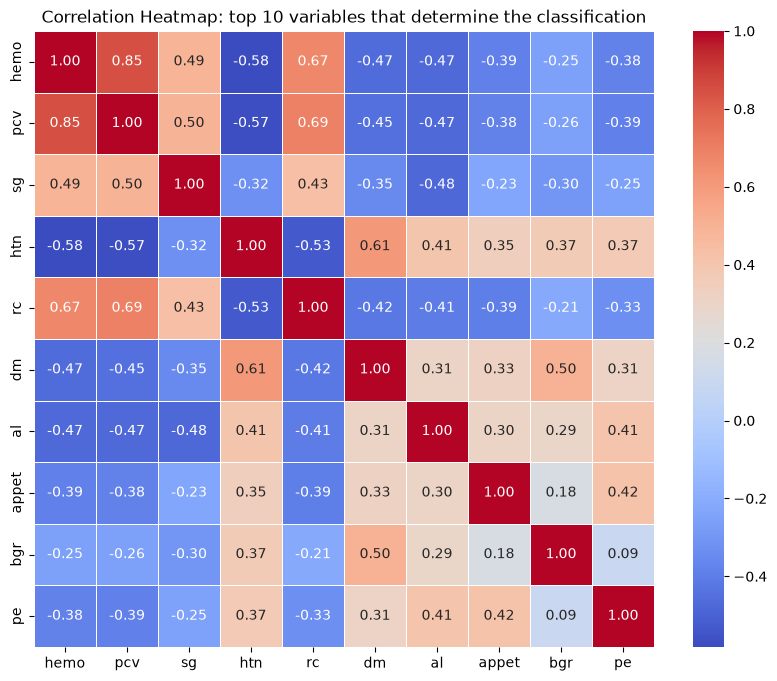

In [4]:
# How strongly each independent variable is related to the target (CKD)
corr_with_target = df.drop(columns='target').corrwith(df['target']).abs().sort_values(ascending=False)
print("Variables most related to the classification:\n")
print(corr_with_target.head(10).round(3))

# Heatmap of those top variables only (target not included)
top_features = corr_with_target.head(10).index.tolist()

plt.figure(figsize=(10, 8))
sns.heatmap(df[top_features].corr(), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap: top 10 variables that determine the classification')
plt.show()

### Step 4b: Overall correlation heatmap
**What this cell does**
- Draws a heatmap of **all 24 independent variables** (the target is not included) to show how every pair of variables is related.

**How to read it:** red = move together, blue = move in opposite directions, and the closer a number is to 1 or -1, the stronger the link.

**Why:** it shows which variables carry similar information (for example, blood-related measurements such as `hemo`, `pcv` and `rc` may be related to each other). Check this on your own plot.

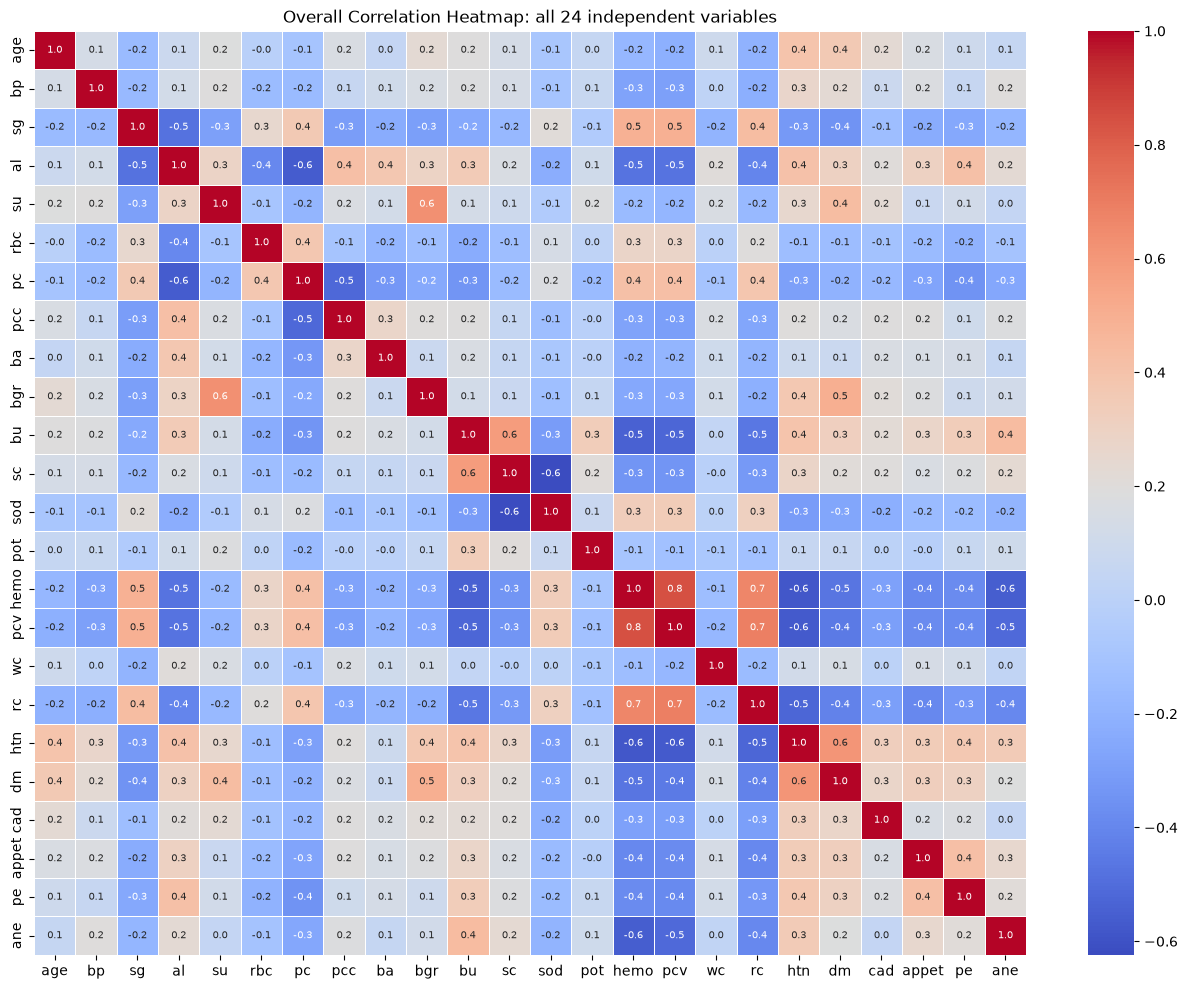

In [5]:
plt.figure(figsize=(16, 12))
sns.heatmap(df.drop(columns='target').corr(), annot=True, fmt='.1f',
            annot_kws={'size': 7}, cmap='coolwarm', linewidths=0.5)
plt.title('Overall Correlation Heatmap: all 24 independent variables')
plt.show()

### Step 5: Exploratory Data Analysis (EDA)
**What this cell does**
- **Chart set 1:** how many patients are CKD vs not CKD, and how hypertension and diabetes relate to CKD.
- **Chart set 2:** histograms showing the spread of `age`, `bp`, `bgr`, `bu`, `sc` and `hemo`.
- **Chart set 3:** box plots of `hemo`, `sc` and `al`, split by CKD / not CKD.

**Why:** we look at the data before building models. If the two boxes in a box plot barely overlap, that feature separates healthy and CKD patients well.

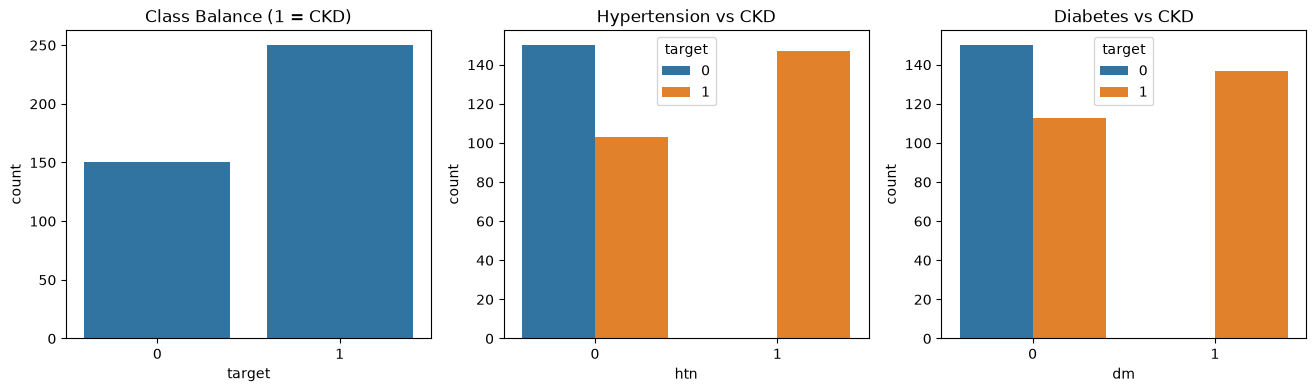

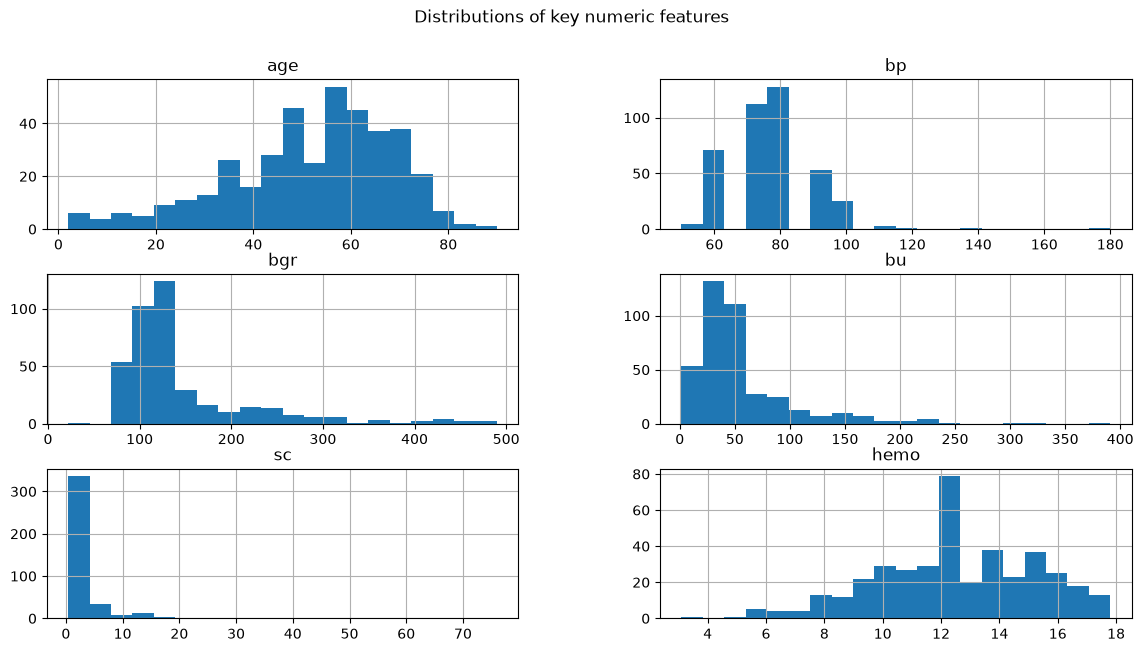

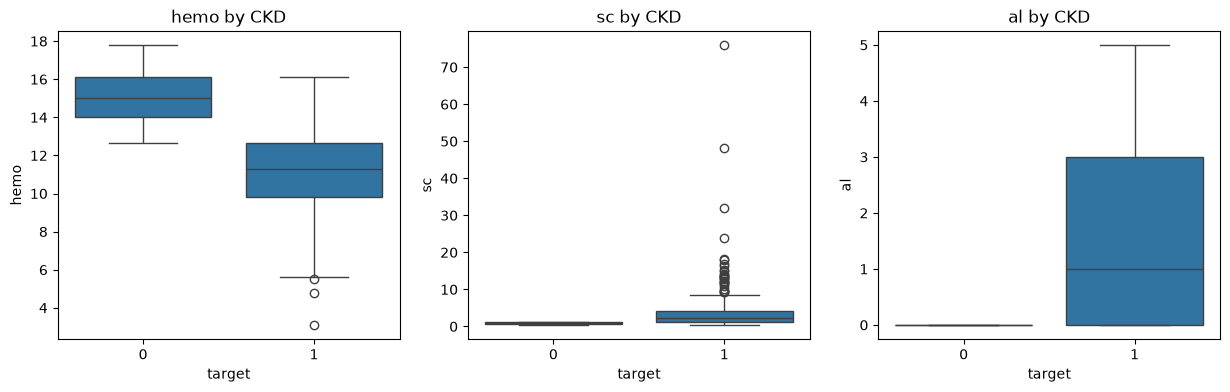

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(x='target', data=df, ax=ax[0]); ax[0].set_title('Class Balance (1 = CKD)')
for a, col, name in zip(ax[1:], ['htn', 'dm'], ['Hypertension', 'Diabetes']):
    if col in df.columns:
        sns.countplot(x=col, hue='target', data=df, ax=a); a.set_title(f'{name} vs CKD')
plt.show()

hist_cols = [c for c in ['age', 'bp', 'bgr', 'bu', 'sc', 'hemo'] if c in df.columns]
df[hist_cols].hist(figsize=(14, 7), bins=20)
plt.suptitle('Distributions of key numeric features'); plt.show()

box_cols = [c for c in ['hemo', 'sc', 'al'] if c in df.columns]
fig, ax = plt.subplots(1, len(box_cols), figsize=(5 * len(box_cols), 4))
for a, col in zip(np.atleast_1d(ax), box_cols):
    sns.boxplot(x='target', y=col, data=df, ax=a); a.set_title(f'{col} by CKD')
plt.show()

### Step 6: Train/Test split
**What this cell does**
- `X` = the 24 input (independent) variables, `y` = the target we want to predict.
- Splits the patients 80% for training and 20% for testing.
- `stratify=y` keeps the same CKD / not-CKD ratio in both parts, and `random_state=42` makes the split repeatable.

**Why:** the test patients are hidden during training, like a final exam, so the scores are honest.

**What you'll see:** 320 patients for training and 80 for testing, each with 24 features.

In [7]:
X = df.drop('target', axis=1)
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (320, 24) | Test: (80, 24)


### Step 7: Model training, 5-fold cross-validation and GridSearchCV
**What this cell does**
- Sets up the 6 models: **KNN, SVM, Decision Tree, Naive Bayes, Logistic Regression, Random Forest**.
- **GridSearchCV** tries many hyperparameter settings for each model, using **5-fold cross-validation** on the training data, and keeps the setting with the best F1 score.
- KNN, SVM and Logistic Regression are wrapped in a pipeline with `StandardScaler`, so scaling is learned only from the training data (this avoids data leakage).
- Each tuned model then **predicts** on the 80 test patients and is scored on accuracy, precision, recall, F1 and ROC AUC.

**What you'll see:** a results table with the best settings for each model (for example, SVM chose `C=1` with the `rbf` kernel) and all the scores side by side.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    'KNN': (Pipeline([('sc', StandardScaler()), ('clf', KNeighborsClassifier())]),
            {'clf__n_neighbors': [3,5,7,9,11], 'clf__weights': ['uniform','distance'],
             'clf__metric': ['euclidean','manhattan']}),
    'SVM': (Pipeline([('sc', StandardScaler()), ('clf', SVC(probability=True, random_state=42))]),
            {'clf__C': [0.1,1,10], 'clf__kernel': ['linear','rbf'], 'clf__gamma': ['scale','auto']}),
    'Decision Tree': (DecisionTreeClassifier(random_state=42),
            {'max_depth': [2,3,4,5,None], 'min_samples_split': [2,5,10],
             'criterion': ['gini','entropy']}),
    'Naive Bayes': (GaussianNB(),
            {'var_smoothing': np.logspace(-9, -1, 9)}),
    'Logistic Regression': (Pipeline([('sc', StandardScaler()), ('clf', LogisticRegression(max_iter=1000))]),
            {'clf__C': [0.01,0.1,1,10,100], 'clf__solver': ['lbfgs','liblinear']}),
    'Random Forest': (RandomForestClassifier(random_state=42),
            {'n_estimators': [100,200], 'max_depth': [3,5,None], 'min_samples_leaf': [1,2,4]}),
}

best_models, rows = {}, []
for name, (model, grid) in models.items():
    gs = GridSearchCV(model, grid, cv=cv, scoring='f1', n_jobs=-1)
    gs.fit(X_train, y_train)
    best = gs.best_estimator_
    best_models[name] = best

    y_pred = best.predict(X_test)
    y_prob = best.predict_proba(X_test)[:, 1]
    cv_acc = cross_val_score(best, X, y, cv=cv, scoring='accuracy')

    rows.append({
        'Model': name,
        'Best Params': gs.best_params_,
        'CV Accuracy (mean)': cv_acc.mean(),
        'CV Std': cv_acc.std(),
        'Test Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC AUC': roc_auc_score(y_test, y_prob),
    })
    print("Done:", name)

results = pd.DataFrame(rows).set_index('Model')
pd.set_option('display.max_colwidth', None)
results.round(3)

Done: KNN
Done: SVM
Done: Decision Tree
Done: Naive Bayes
Done: Logistic Regression
Done: Random Forest


,Best Params,CV Accuracy (mean),CV Std,Test Accuracy,Precision,Recall,F1,ROC AUC
Model,,,,,,,,
KNN,"{'clf__metric': 'manhattan', 'clf__n_neighbors': 3, 'clf__weights': 'uniform'}",0.960,0.015,0.962,1.00,0.94,0.969,0.990
SVM,"{'clf__C': 1, 'clf__gamma': 'scale', 'clf__kernel': 'rbf'}",0.988,0.008,0.988,1.00,0.98,0.990,1.000
Decision Tree,"{'criterion': 'gini', 'max_depth': 3, 'min_samples_split': 2}",0.978,0.015,0.975,0.98,0.98,0.980,0.989
Naive Bayes,{'var_smoothing': 1e-09},0.965,0.018,0.975,1.00,0.96,0.980,1.000
Logistic Regression,"{'clf__C': 1, 'clf__solver': 'lbfgs'}",0.997,0.005,0.988,1.00,0.98,0.990,1.000
Random Forest,"{'max_depth': 3, 'min_samples_leaf': 1, 'n_estimators': 200}",0.990,0.009,0.988,0.98,1.00,0.990,1.000


### Step 8: Evaluation: model comparison chart
**What this cell does**
- Draws grouped bars comparing Accuracy, Precision, Recall, F1 and ROC AUC for all 6 models.

**How to read it:** higher bars are better. This is the quickest visual comparison of the models.

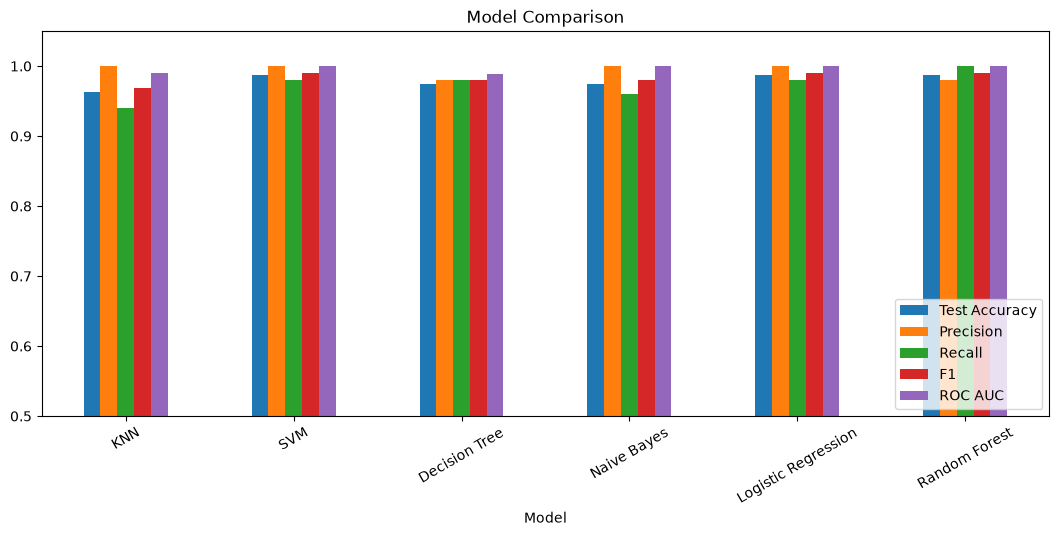

In [9]:
metrics = ['Test Accuracy', 'Precision', 'Recall', 'F1', 'ROC AUC']
results[metrics].plot(kind='bar', figsize=(13, 5), ylim=(0.5, 1.05))
plt.title('Model Comparison'); plt.xticks(rotation=30); plt.legend(loc='lower right')
plt.show()

### Step 9: Confusion matrices
**What this cell does**
- Draws one confusion matrix for each model (a 2 x 3 grid).

**How to read each box:**
- Top-left: correctly predicted **No CKD**.
- Bottom-right: correctly predicted **CKD**.
- Top-right: **false alarm** (healthy patient predicted as CKD).
- Bottom-left: **missed patient** (CKD patient predicted as healthy). This is the most dangerous error in medicine.

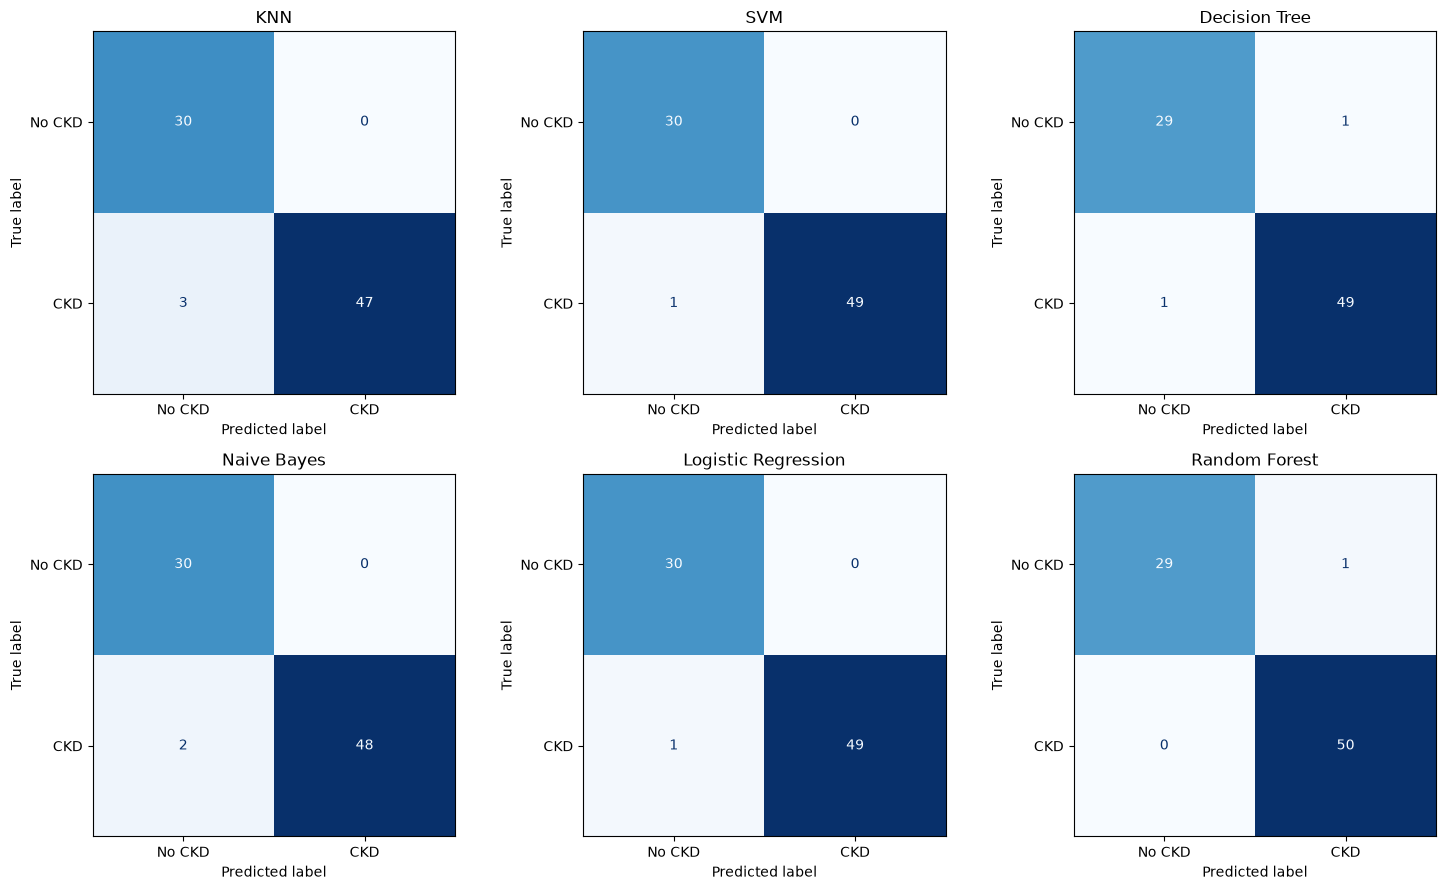

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, m) in zip(axes.ravel(), best_models.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, m.predict(X_test)),
                           display_labels=['No CKD', 'CKD']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

### Step 10: ROC curves
**What this cell does**
- Draws one ROC curve per model. Each curve shows the trade-off between catching real CKD patients (true positive rate) and raising false alarms (false positive rate).
- The dotted diagonal line is random guessing.

**How to read it:** the closer a curve is to the top-left corner (and the closer its AUC is to 1.0), the better the model separates CKD from healthy patients.

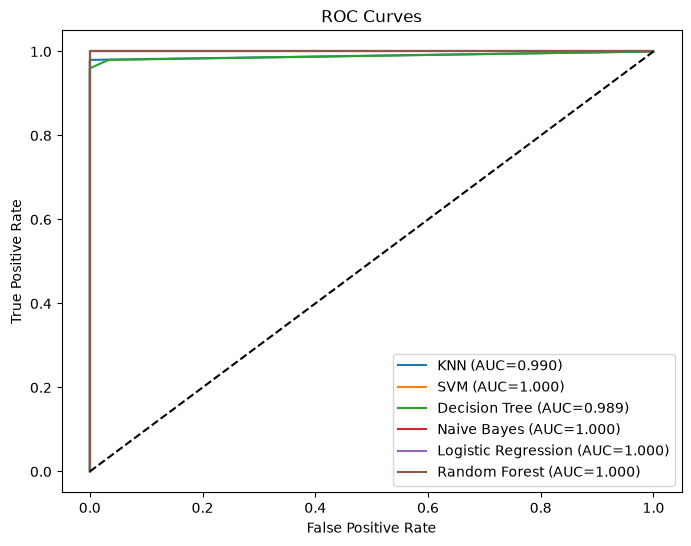

In [11]:
plt.figure(figsize=(8, 6))
for name, m in best_models.items():
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=f"{name} (AUC={results.loc[name,'ROC AUC']:.3f})")
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curves'); plt.legend(); plt.show()

### Step 11: Prediction comparison across models
**What this cell does**
- Makes a table with the actual answer and each model's prediction for every test patient.
- Counts how many of the 6 models got each patient right, and whether all models agree.

**What you'll see:** all 6 models agree and are correct on **92.5%** of the test patients, and there is no patient that all 6 models got wrong. The table shows the first 15 patients.

In [12]:
model_cols = list(best_models.keys())

preds = pd.DataFrame({'Actual': y_test.values}, index=X_test.index)
for name, m in best_models.items():
    preds[name] = m.predict(X_test)

correct = preds[model_cols].eq(preds['Actual'], axis=0)
preds['Models Correct (of 6)'] = correct.sum(axis=1)
preds['All Agree'] = preds[model_cols].nunique(axis=1) == 1

print(f"All 6 models agree on {preds['All Agree'].mean()*100:.1f}% of test patients")
print(f"All 6 models correct on {(preds['Models Correct (of 6)']==6).mean()*100:.1f}%")
print(f"All 6 models wrong on {(preds['Models Correct (of 6)']==0).mean()*100:.1f}%")
preds.head(15)

All 6 models agree on 92.5% of test patients
All 6 models correct on 92.5%
All 6 models wrong on 0.0%


,Actual,KNN,SVM,Decision Tree,Naive Bayes,Logistic Regression,Random Forest,Models Correct (of 6),All Agree
342,0,0,0,0,0,0,0,6,True
204,1,1,1,1,1,1,1,6,True
233,1,1,1,1,1,1,1,6,True
366,0,0,0,0,0,0,0,6,True
120,1,1,1,1,1,1,1,6,True
29,1,1,1,1,1,1,1,6,True
399,0,0,0,0,0,0,0,6,True
219,1,1,1,1,1,1,1,6,True
216,1,1,1,1,0,1,1,5,False
115,1,1,1,1,1,1,1,6,True


### Step 12: Hard-to-classify patients
**What this cell does**
- Picks out the test patients that 2 or fewer models predicted correctly, and shows their medical values.

**What you'll see:** only **1 patient** (row 102). Only the Decision Tree and Random Forest got this CKD patient right. Its lab values (for example `hemo` 13.9 and `pcv` 52) look healthy, which may be why most models predicted "No CKD".

In [13]:
hard = preds[preds['Models Correct (of 6)'] <= 2]
print("Hard-to-classify patients:", len(hard))
display(pd.concat([hard, X_test.loc[hard.index]], axis=1))

Hard-to-classify patients: 1


,Actual,KNN,SVM,Decision Tree,Naive Bayes,Logistic Regression,Random Forest,Models Correct (of 6),All Agree,age,...,hemo,pcv,wc,rc,htn,dm,cad,appet,pe,ane
102,1,0,0,1,0,0,1,2,False,17.0,...,13.9,52.0,7000.0,4.8,0,0,0,0,0,0


### Step 13: Error breakdown (TP, TN, FP, FN)
**What this cell does**
- Counts, for each model, the correct CKD predictions (TP), correct No-CKD predictions (TN), false alarms (FP) and **missed CKD patients (FN)**.

**Why it matters:** in a medical problem, missing a sick patient (FN) is the costly mistake, so this table matters more than accuracy alone.

**What you'll see:** Random Forest missed **0** CKD patients (with 1 false alarm), while KNN missed 3.

In [14]:
err_rows = []
for name, m in best_models.items():
    tn, fp, fn, tp = confusion_matrix(y_test, m.predict(X_test)).ravel()
    err_rows.append({'Model': name, 'TP': tp, 'TN': tn, 'FP (false alarm)': fp, 'FN (missed patient)': fn})
err_df = pd.DataFrame(err_rows).set_index('Model')
err_df

,TP,TN,FP (false alarm),FN (missed patient)
Model,,,,
KNN,47,30,0,3
SVM,49,30,0,1
Decision Tree,49,29,1,1
Naive Bayes,48,30,0,2
Logistic Regression,49,30,0,1
Random Forest,50,29,1,0


### Step 14: Final model ranking
**What this cell does**
- Sorts the models by F1 score (ties are broken by ROC AUC) and gives each a rank from 1 to 6.
- Shades the table green: darker green means a better score.

**What you'll see:** the best model on top, with CV accuracy, test accuracy, precision, recall, F1 and ROC AUC for every model.

In [15]:
rank_metrics = ['CV Accuracy (mean)', 'Test Accuracy', 'Precision', 'Recall', 'F1', 'ROC AUC']
ranking = results[rank_metrics].sort_values(['F1', 'ROC AUC'], ascending=False)
ranking.insert(0, 'Rank', range(1, len(ranking) + 1))
ranking.round(3).style.background_gradient(cmap='Greens', subset=rank_metrics)

,Rank,CV Accuracy (mean),Test Accuracy,Precision,Recall,F1,ROC AUC
Model,,,,,,,
Random Forest,1,0.990000,0.988000,0.980000,1.000000,0.990000,1.000000
SVM,2,0.988000,0.988000,1.000000,0.980000,0.990000,1.000000
Logistic Regression,3,0.997000,0.988000,1.000000,0.980000,0.990000,1.000000
Decision Tree,4,0.978000,0.975000,0.980000,0.980000,0.980000,0.989000
Naive Bayes,5,0.965000,0.975000,1.000000,0.960000,0.980000,1.000000
KNN,6,0.960000,0.962000,1.000000,0.940000,0.969000,0.990000


### Step 15: Stability across the 5 folds
**What this cell does**
- Runs 5-fold cross-validation again for each tuned model and records the F1 score of every fold, in a table and a box plot.

**How to read it:** a model whose scores stay almost the same in all 5 folds (a narrow box) is more stable and reliable than one with big ups and downs.

,KNN,SVM,Decision Tree,Naive Bayes,Logistic Regression,Random Forest
Fold 1,0.969,0.99,0.99,0.980,1.00,0.99
Fold 2,0.980,0.99,1.00,0.980,1.00,1.00
Fold 3,0.947,0.98,0.97,0.958,0.99,0.98
Fold 4,0.980,1.00,0.97,0.990,1.00,0.99
Fold 5,0.958,0.99,0.98,0.947,1.00,1.00


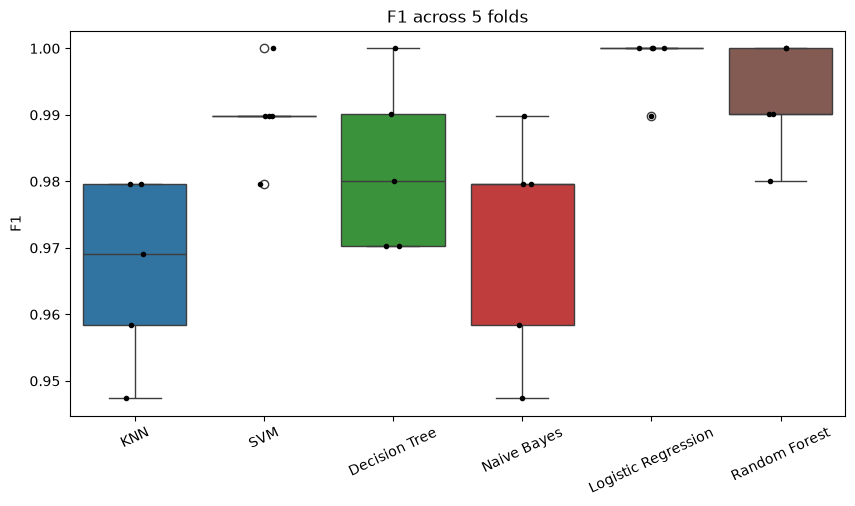

In [16]:
fold_scores = pd.DataFrame({n: cross_val_score(m, X, y, cv=cv, scoring='f1')
                            for n, m in best_models.items()})
fold_scores.index = [f'Fold {i}' for i in range(1, 6)]
display(fold_scores.round(3))

plt.figure(figsize=(10, 5))
sns.boxplot(data=fold_scores)
sns.stripplot(data=fold_scores, color='black', size=4)
plt.title('F1 across 5 folds'); plt.xticks(rotation=25); plt.ylabel('F1')
plt.show()

### Step 16: Automatic conclusion
**What this cell does**
- Prints a summary: the best model, the model with the fewest missed patients, the most stable model and the weakest model.

**What you'll see:**
- Best overall: **Random Forest** (F1 = 0.990, AUC = 1.000).
- Fewest missed patients: **Random Forest**.
- Most stable across folds: **Logistic Regression**.
- Weakest by F1: **KNN**.

In [17]:
best = ranking.index[0]
print(f"Best overall (F1, then AUC): {best} | F1 = {ranking.loc[best,'F1']:.3f} | AUC = {ranking.loc[best,'ROC AUC']:.3f}")
print(f"Fewest missed patients (lowest FN): {err_df['FN (missed patient)'].idxmin()}")
print(f"Most stable across folds (lowest std): {fold_scores.std().idxmin()}")
print(f"Weakest model by F1: {ranking.index[-1]}")

Best overall (F1, then AUC): Random Forest | F1 = 0.990 | AUC = 1.000
Fewest missed patients (lowest FN): Random Forest
Most stable across folds (lowest std): Logistic Regression
Weakest model by F1: KNN


## Explainable AI (XAI)
**What is it?**
- Accuracy tells us *how often* a model is right, but not *why* it made a decision. In healthcare, a doctor needs the reasons before trusting a prediction.
- **Explainable AI** = methods that show **which features pushed a model's decision, and in which direction**.

**Two levels of explanation**
- **Global:** which features matter most for the model overall.
- **Local:** why the model made its decision for **one specific patient**.

**Methods used in this project**
| Method | Level | Where |
|---|---|---|
| Random Forest feature importance | Global | Step 17 |
| Permutation importance | Global | Step 17 |
| Decision tree (readable rules) | Global | Step 18 |
| **SHAP** (summary, violin, bar, dependence, single patient) | Global and Local | Steps 19-25 |

### Step 17: Explainable AI (part 1): feature importance
**What this cell does**
- **Random Forest feature importance:** shows how much each feature helped the forest make its decisions.
- **Permutation importance:** randomly shuffles one feature at a time on the test data and measures how much the F1 score drops. A bigger drop means the model relies on that feature more.

**Why:** this explains **why** the model predicts CKD, not just how accurate it is. That is the "Explainable AI" part.

Best model: Random Forest


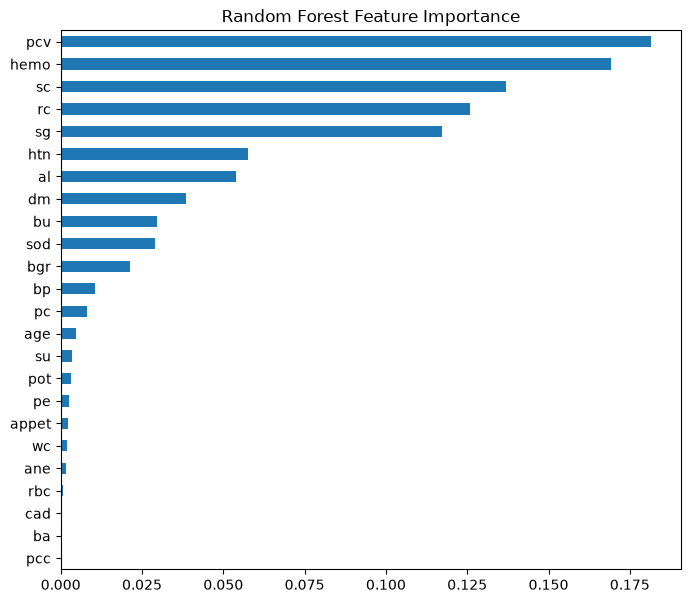

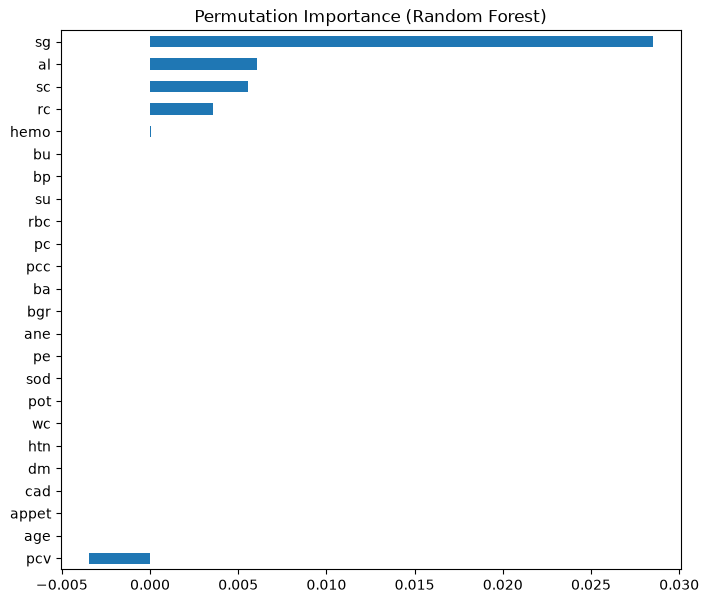

In [18]:
best_name = ranking.index[0]
print("Best model:", best_name)

# Random Forest feature importance
rf = best_models['Random Forest']
pd.Series(rf.feature_importances_, index=X.columns).sort_values().plot(kind='barh', figsize=(8, 7))
plt.title('Random Forest Feature Importance'); plt.show()

# Permutation importance on the best model
perm = permutation_importance(best_models[best_name], X_test, y_test,
                              n_repeats=20, random_state=42, scoring='f1')
pd.Series(perm.importances_mean, index=X.columns).sort_values().plot(kind='barh', figsize=(8, 7))
plt.title(f'Permutation Importance ({best_name})'); plt.show()

### Step 18: Explainable AI (part 2): decision tree
**What this cell does**
- Draws the trained Decision Tree as a flowchart.

**How to read it:** each box asks a yes/no question about one feature. Follow the branches down to a final decision of CKD or No CKD, and the colour shows which class that box mostly contains. It is the easiest model to explain, because every decision is a simple rule.

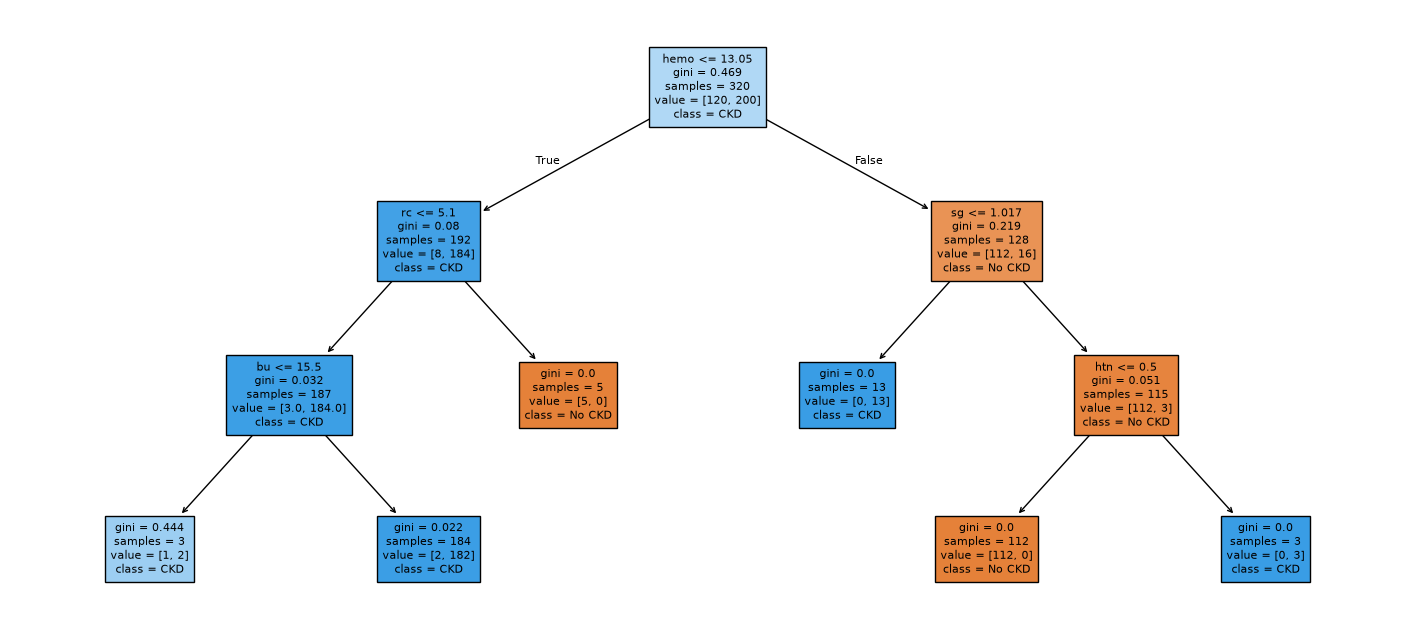

In [19]:
plt.figure(figsize=(18, 8))
plot_tree(best_models['Decision Tree'], feature_names=X.columns,
          class_names=['No CKD', 'CKD'], filled=True, fontsize=8)
plt.show()

### Step 19: SHAP, what is it?
**What SHAP does**
- SHAP (SHapley Additive exPlanations) gives **every feature a score for every patient**: how much did this feature push the prediction **toward CKD** or **toward No CKD**?
- It comes from game theory: the features are like players in a team, and SHAP shares the "credit" for the final prediction fairly among them.
- **Positive SHAP value = pushes toward CKD. Negative = pushes toward No CKD.**

**What this cell does**
- Loads SHAP. If it is not installed, the cell tries to install it into this notebook's Python automatically (about a minute).
- If the install fails, the error is printed and the SHAP cells below are skipped, so the rest of the notebook still works.

In [20]:
try:
    import shap
except ImportError:
    import subprocess, sys, importlib
    print("SHAP not found - installing it now (this can take about a minute)...")
    result = subprocess.run([sys.executable, '-m', 'pip', 'install', 'shap'],
                            capture_output=True, text=True)
    if result.returncode == 0:
        importlib.invalidate_caches()
        try:
            import shap
        except ImportError:
            shap = None
    else:
        shap = None
        print("Install failed. Last lines of the error:\n", result.stdout[-600:], result.stderr[-600:])

if shap is not None:
    print("SHAP ready, version", shap.__version__)
else:
    print("SHAP is unavailable - the SHAP cells below will be skipped.")

SHAP ready, version 0.52.0


### Step 20: Calculate the SHAP values
**What this cell does**
- Builds a SHAP explainer for the **Random Forest** (the best model).
- Calculates a SHAP value for **every feature of every test patient** (80 patients x 24 features).
- Keeps the values for the **CKD class**, so a positive value means "pushes toward CKD" and a negative value means "pushes toward No CKD".

All the SHAP plots below are drawn from these numbers.

In [21]:
if shap is None:
    print("Skipped: SHAP is not installed.")
else:
    rf = best_models['Random Forest']
    explainer = shap.TreeExplainer(rf)
    sv = explainer.shap_values(X_test)

    # Different SHAP versions return different shapes; take the values for class 1 (CKD)
    if isinstance(sv, list):
        sv_ckd = sv[1]
    elif sv.ndim == 3:
        sv_ckd = sv[:, :, 1]
    else:
        sv_ckd = sv

    base_value = explainer.expected_value
    base_value = base_value[1] if np.ndim(base_value) > 0 else base_value
    print("SHAP values calculated:", sv_ckd.shape, "(test patients x features)")

SHAP values calculated: (80, 24) (test patients x features)


### Step 21: SHAP summary plot (beeswarm): global explanation
**What this cell does**
- Draws the **SHAP summary (beeswarm) plot** for the top 10 features and saves it as `shap_summary_beeswarm.png`.

**How to read the plot**
- Each dot is **one test patient** for one feature. Features are sorted from most important (top) to least important (bottom).
- **Left-right position** = SHAP value (impact on model output). Right = pushes toward **CKD**, left = pushes toward **No CKD**.
- **Colour** = the feature's actual value: red = high, blue = low. So you can see whether high or low values of a feature push toward CKD.

**How to say it:** "The features at the top influence the model's decisions the most, and the colours show in which direction."


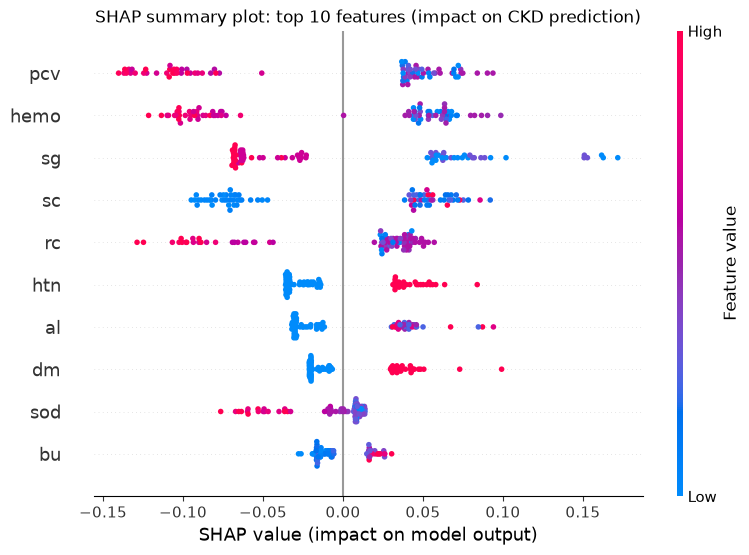

In [22]:
if shap is None:
    print("Skipped: SHAP is not installed.")
else:
    shap.summary_plot(sv_ckd, X_test, max_display=10, show=False)
    plt.title('SHAP summary plot: top 10 features (impact on CKD prediction)')
    plt.savefig('shap_summary_beeswarm.png', dpi=300, bbox_inches='tight')
    plt.show()

### Step 22: SHAP violin plot
**What this cell does**
- Shows the same information as the beeswarm plot, drawn as smooth **violin shapes** instead of dots, and saves it as `shap_summary_violin.png`.

**How to read it:** a wider part of a violin means more patients had that SHAP impact. Colours and left-right direction mean the same as in Step 21.

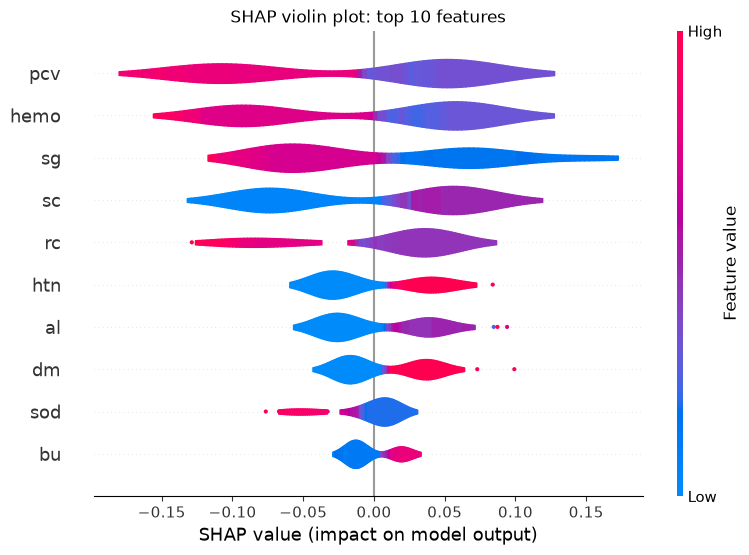

In [23]:
if shap is None:
    print("Skipped: SHAP is not installed.")
else:
    shap.summary_plot(sv_ckd, X_test, plot_type='violin', max_display=10, show=False)
    plt.title('SHAP violin plot: top 10 features')
    plt.savefig('shap_summary_violin.png', dpi=300, bbox_inches='tight')
    plt.show()

### Step 23: SHAP bar plot (average importance)
**What this cell does**
- Shows the **average size of the push** (mean absolute SHAP value) each feature gives to the prediction, and saves it as `shap_bar.png`. A longer bar means a more important feature.

**Why:** it is a simple ranking you can compare with the importance charts in Step 17. If the same features are at the top in all of them, we can trust that those features really drive the model.

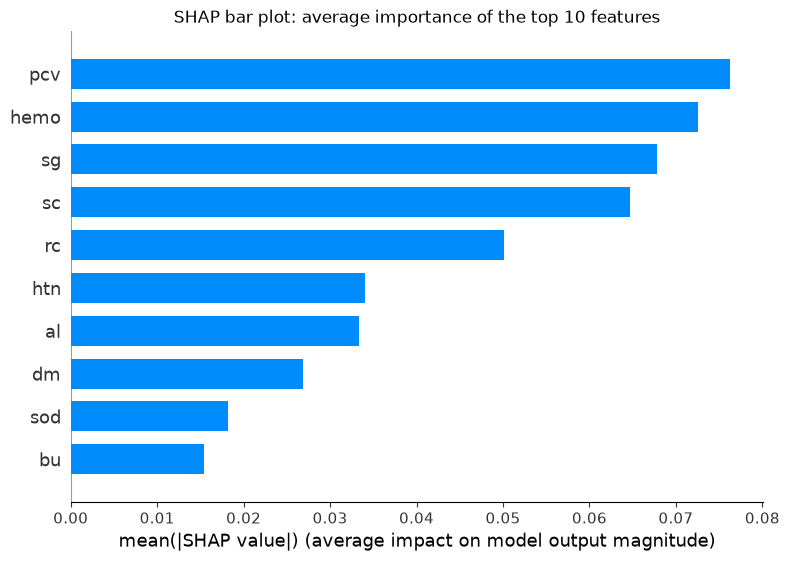

In [24]:
if shap is None:
    print("Skipped: SHAP is not installed.")
else:
    shap.summary_plot(sv_ckd, X_test, plot_type='bar', max_display=10, show=False)
    plt.title('SHAP bar plot: average importance of the top 10 features')
    plt.savefig('shap_bar.png', dpi=300, bbox_inches='tight')
    plt.show()

### Step 24: SHAP dependence plot (most important feature)
**What this cell does**
- Finds the feature with the biggest average SHAP impact and draws its **dependence plot**, saved as `shap_dependence.png`.

**How to read it**
- X-axis = the feature's actual value, y-axis = its SHAP value (impact on the prediction). Each dot is one patient.
- It shows **how the value of one feature changes the prediction**: above 0 pushes toward CKD, below 0 toward No CKD.
- The colour is a second feature that SHAP picked because it interacts with this one.

Most important feature according to SHAP: pcv


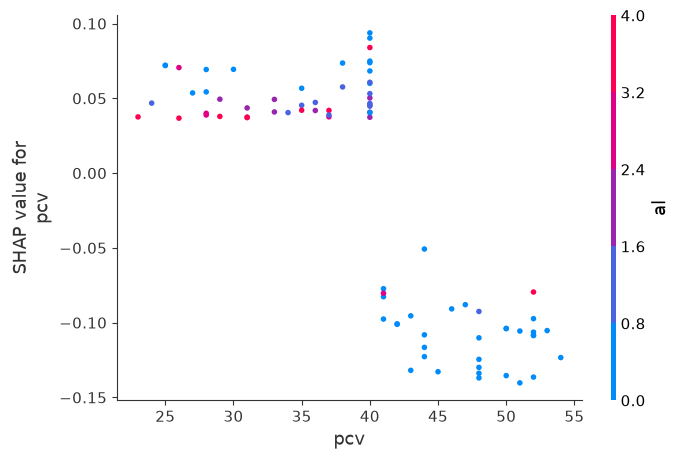

In [25]:
if shap is None:
    print("Skipped: SHAP is not installed.")
else:
    top_feature = pd.Series(np.abs(sv_ckd).mean(axis=0), index=X_test.columns).idxmax()
    print("Most important feature according to SHAP:", top_feature)
    shap.dependence_plot(top_feature, sv_ckd, X_test, show=False)
    plt.savefig('shap_dependence.png', dpi=300, bbox_inches='tight')
    plt.show()

### Step 25: SHAP explanation for ONE patient (local explanation)
**What this cell does**
- Explains the Random Forest's prediction for a single patient, saved as `shap_waterfall.png`. By default this is the **hard-to-classify patient (row 102)** from Step 12, the one that most models got wrong. Change `patient_idx` to explain any other test patient.

**How to read the waterfall plot**
- It starts at the **average prediction** for all patients (`E[f(X)]`).
- Each bar shows how one feature **pushed this patient's prediction up or down**: **red bars push toward CKD** and **blue bars push toward No CKD**.
- It ends at `f(x)`, the model's final CKD probability for this patient.

**Why:** this is the main advantage of SHAP. It can tell a doctor exactly **why** the model made a decision for **this** patient.

Patient row: 102 | Actual: 1 | Random Forest predicted: 1


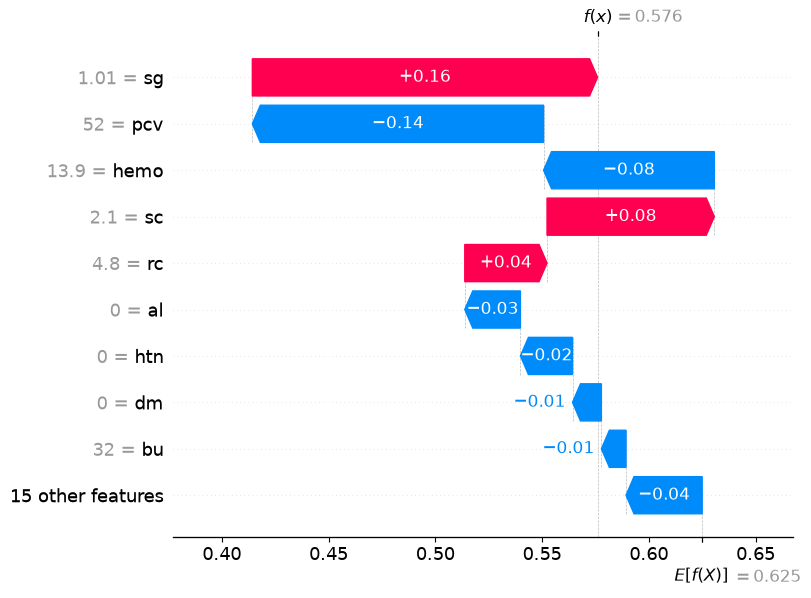

In [26]:
if shap is None:
    print("Skipped: SHAP is not installed.")
else:
    patient_idx = 102                      # change this to explain a different patient
    if patient_idx not in X_test.index:    # safety: fall back to the first test patient
        patient_idx = X_test.index[0]
    pos = X_test.index.get_loc(patient_idx)

    print("Patient row:", patient_idx, "| Actual:", y_test.loc[patient_idx],
          "| Random Forest predicted:", rf.predict(X_test.iloc[[pos]])[0])

    explanation = shap.Explanation(values=sv_ckd[pos], base_values=base_value,
                                   data=X_test.iloc[pos].values,
                                   feature_names=X_test.columns.tolist())
    shap.plots.waterfall(explanation, max_display=10, show=False)
    plt.savefig('shap_waterfall.png', dpi=300, bbox_inches='tight')
    plt.show()